# Digital Image Processing Project
This project aims to use different digital image processing techniques in a self-created database.


## 1- Database

The database consists of 40 images of fruits, being 10 different fruits (classes) in 2 different positions for a black and a white background, the fruits identifiers are:

| ID | Fruit Class|
|----|------------|
| 0  | Strawberry |
| 1  | Banana     |
| 2  | Mango      |
| 3  | Orange     |
| 4  | Grape      |
| 5  | Pear       |
| 6  | Mandarin   |
| 7  | Apple      |
| 8  | Peach      |
| 9  | Guava      |

The image name follows the pattern "id-seq-v-bg.png", where:

- id: Fruit Class ID
- seq: Image Sequence
- v: Version/Position (V1|V2)
- bg: Background (W = White|B = Black)

## 2- Data Annotation

### Parse XML Annotations into a Dictionary

In [ ]:
import xml.etree.ElementTree as ET
import os

tree = ET.parse('annotations.xml')
root = tree.getroot()
annotations = {}

image_nodes = root.findall('.//image')
for img in image_nodes:
  filename = img.get('name')
  box = img.find('box')
  xtl = int(float(box.get('xtl')))
  ytl = int(float(box.get('ytl')))
  xbr = int(float(box.get('xbr')))
  ybr = int(float(box.get('ybr')))
  label = box.get('label')
  annotations[filename] = (xtl, ytl, xbr, ybr, label)

### Show Images with Bounding Boxes

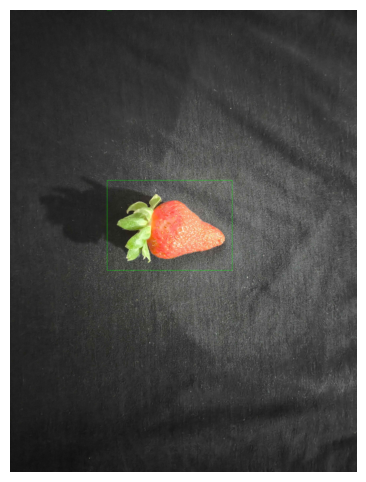

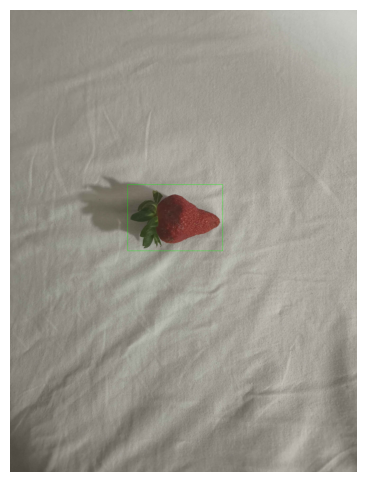

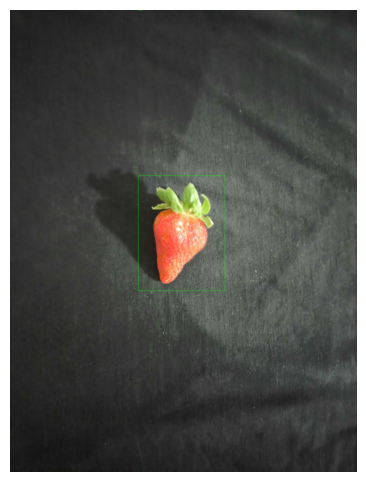

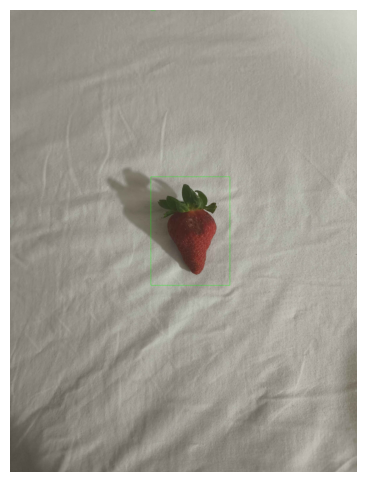

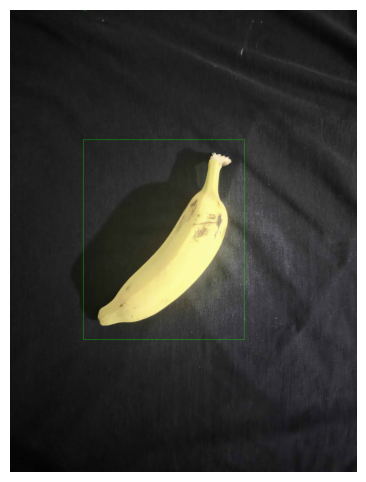

...

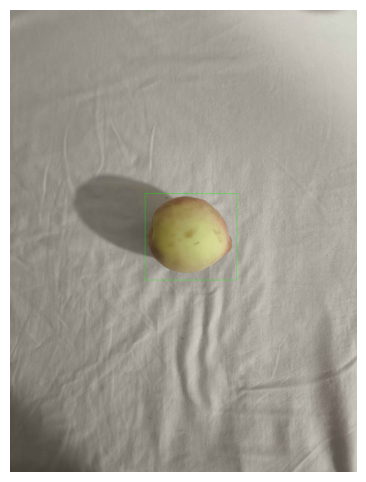

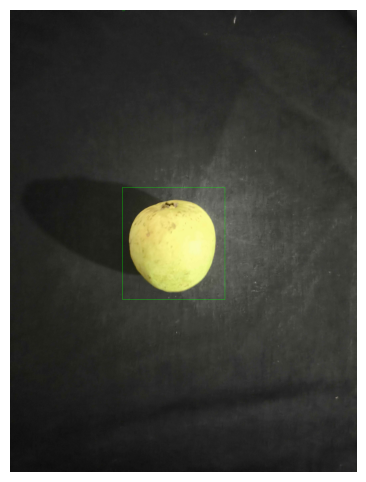

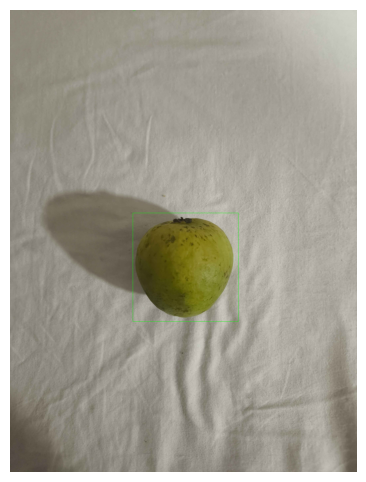

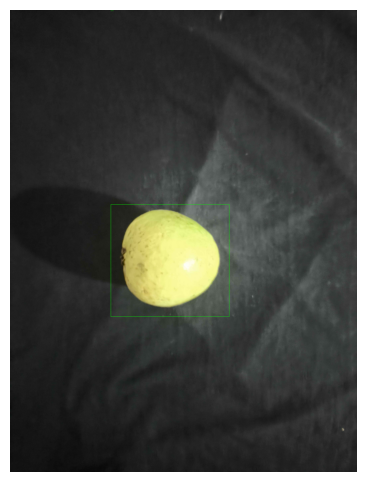

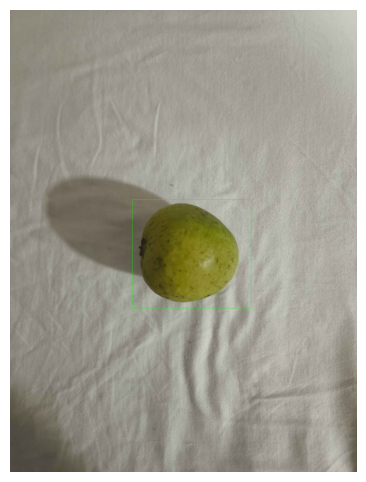

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

for filename, boxes in annotations.items():
  img_path = os.path.join('database', filename)
  xtl, ytl, xbr, ybr, label = boxes

  img = Image.open(img_path).convert('RGB')
  draw = ImageDraw.Draw(img)
  draw.rectangle([xtl, ytl, xbr, ybr], outline='lime', width=3)
  draw.text((xtl, min(ytl-12, 0)), label, fill='lime')

  plt.figure(figsize=(8,6))
  plt.imshow(img)
  plt.axis('off')
  plt.show()

## 3- Data Augmentation

### Load Images as Numpy Arrays

In [1]:
from PIL import Image
import numpy as np
import os

images = []

image_names = os.listdir('database')
for image in image_names:
  path = os.path.join('database', image)
  img = Image.open(path).convert('RGB')
  images.append(np.array(img))

### Data Augmentation Functions

In [ ]:
import numpy as np
from PIL import Image, ImageFilter

def log_transform(img: np.ndarray) -> np.ndarray:
    r = img.astype(np.float32) / 255.0
    s = np.log1p(r) / np.log(2.0)
    return np.clip(s * 255.0, 0, 255).astype(np.uint8)

def exp_transform(img: np.ndarray) -> np.ndarray:
    r = img.astype(np.float32) / 255.0
    s = (np.exp(r) - 1.0) / (np.e - 1.0)
    return np.clip(s * 255.0, 0, 255).astype(np.uint8)

def mean_filter(img: np.ndarray, size: int = 3) -> np.ndarray:
    radius = (size - 1) // 2
    pil_img = Image.fromarray(img)
    filtered = pil_img.filter(ImageFilter.BoxBlur(radius))
    return np.array(filtered)

### Augment Images and Show Function

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

log_images = []
exp_images = []
mfr_images = []

for image in images:
  log_images.append(log_transform(image))
  exp_images.append(exp_transform(image))
  mfr_images.append(mean_filter(image))

def show_images(image_dataset):
  for img in image_dataset:
    pil_img = Image.fromarray(img)
    plt.figure(figsize=(8,6))
    plt.imshow(pil_img)
    plt.axis('off')
    plt.show()

### Log Augmentation

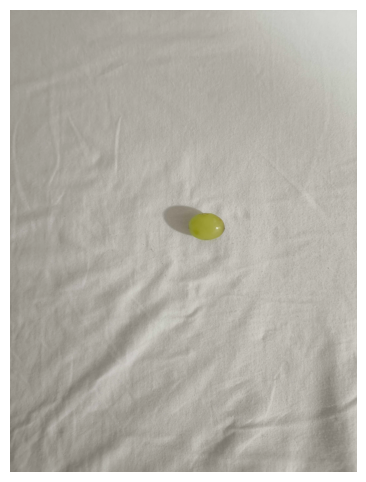

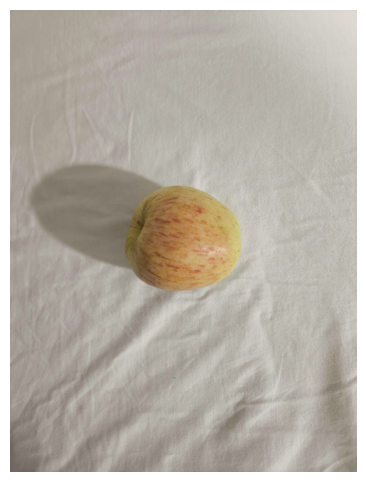

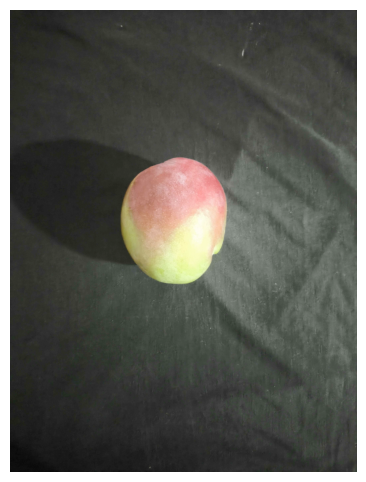

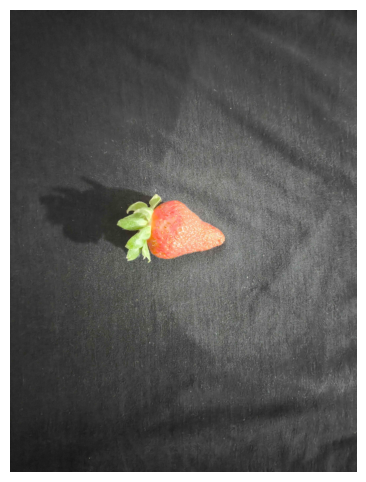

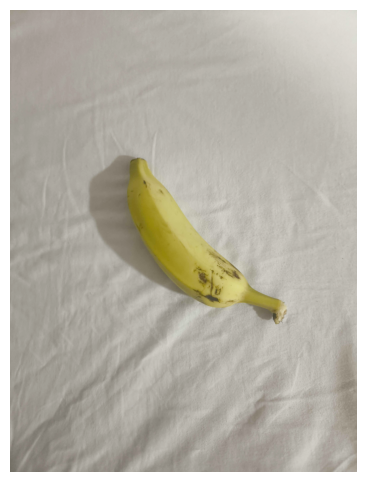

...

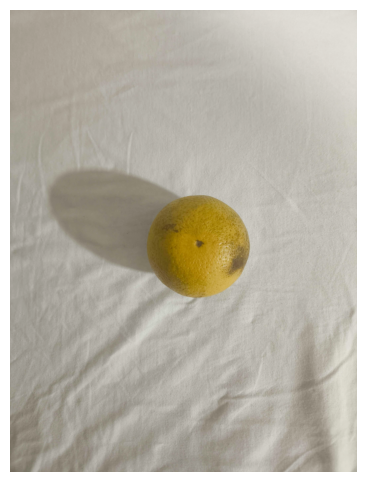

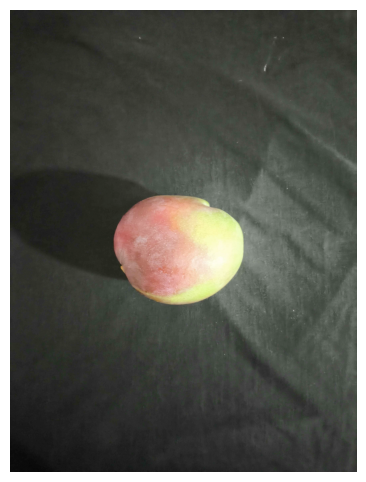

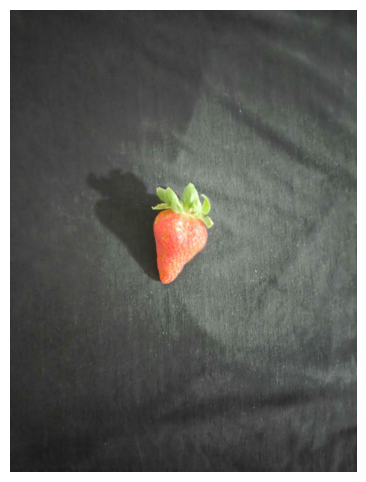

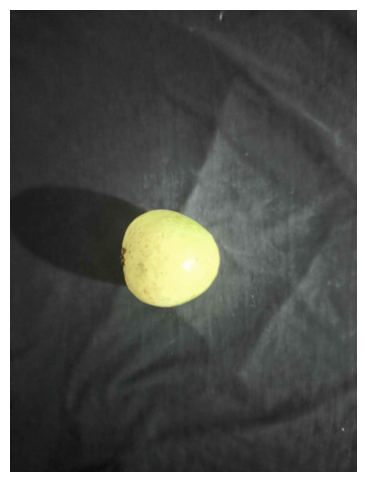

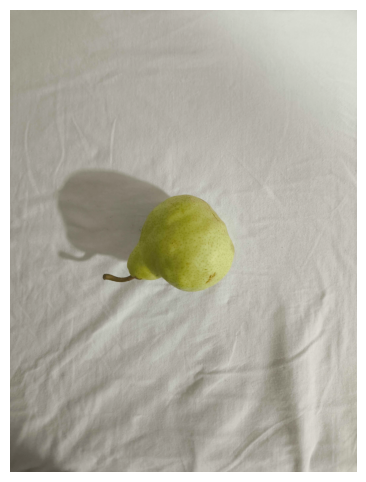

In [ ]:
show_images(log_images)

### Exp Augmentation

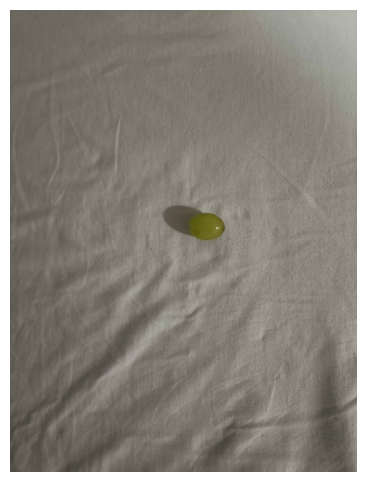

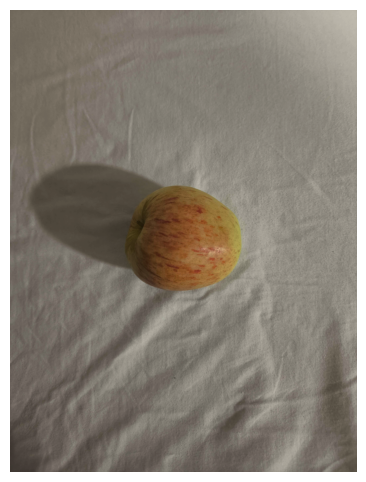

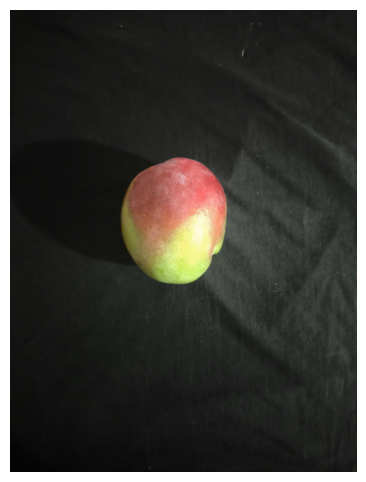

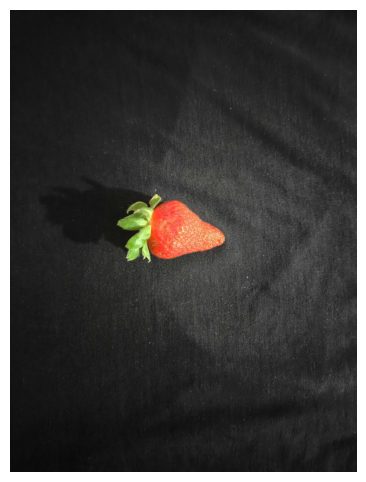

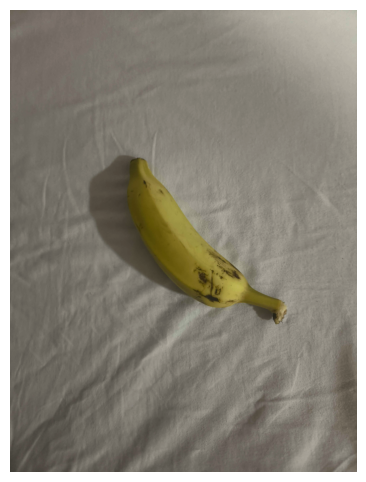

...

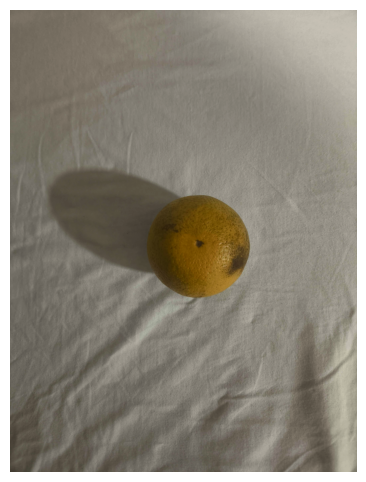

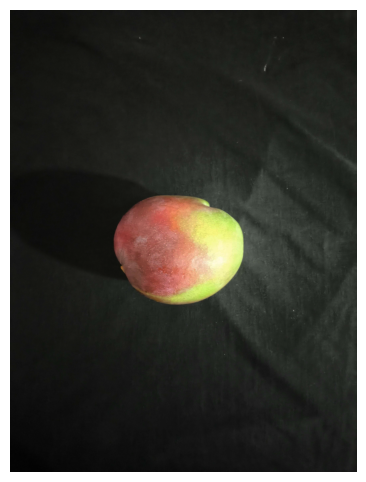

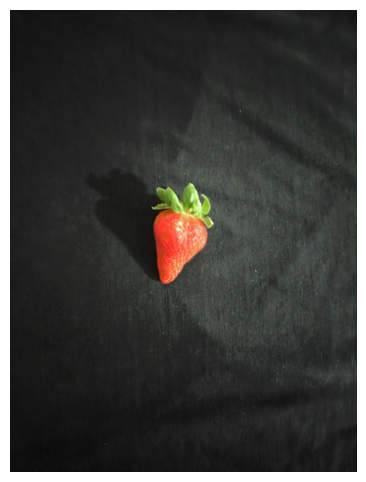

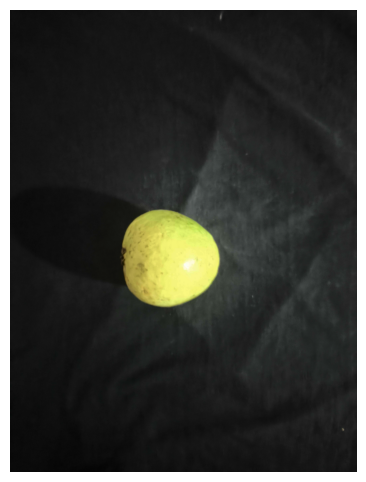

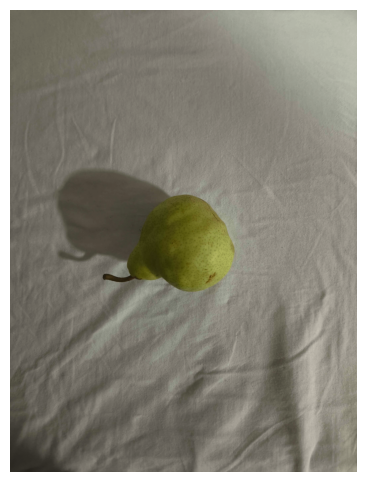

In [ ]:
show_images(exp_images)

### Mean Filter

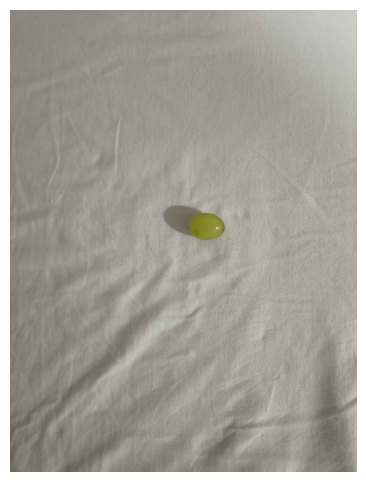

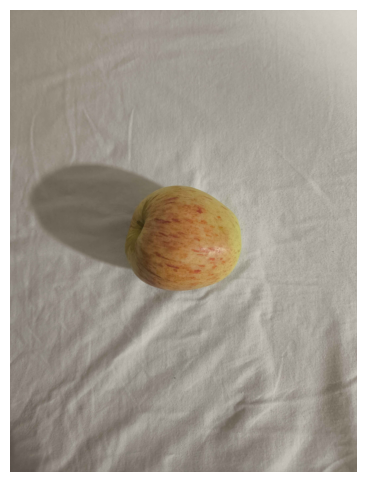

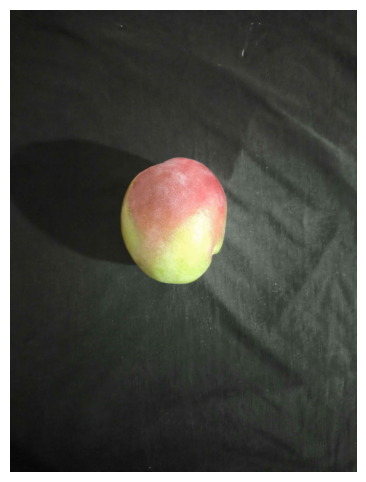

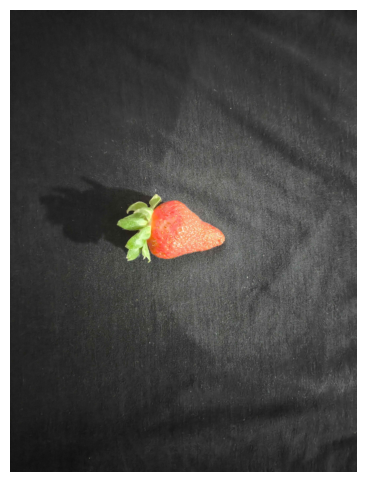

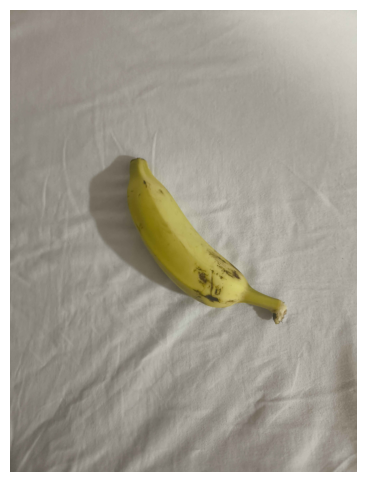

...

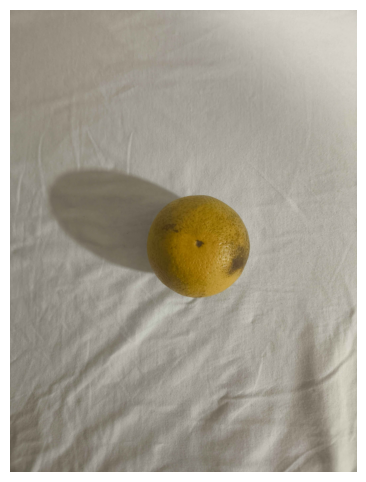

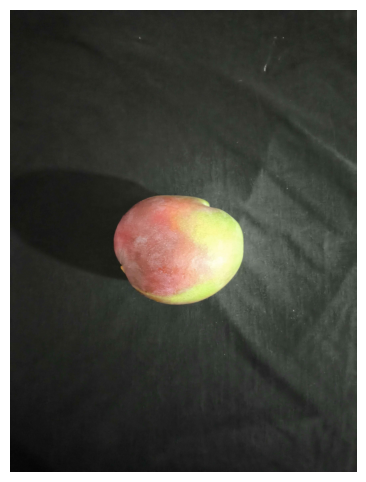

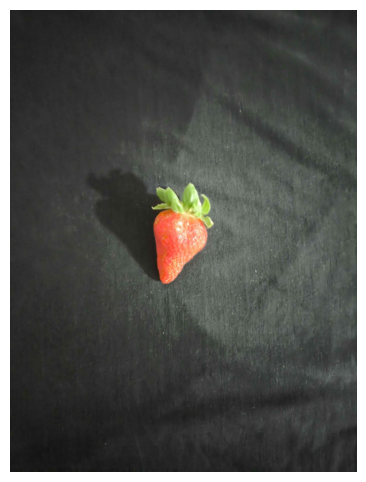

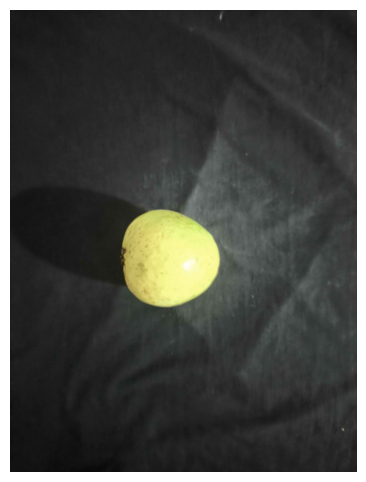

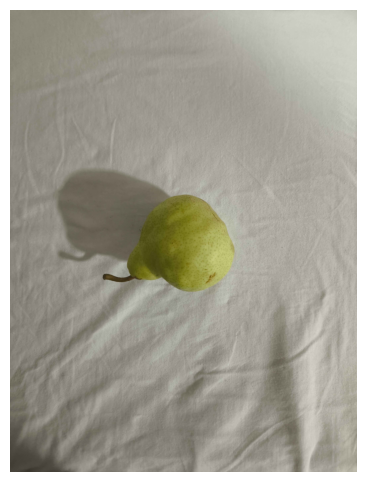

In [ ]:
show_images(mfr_images)

## 4- Data Normalization

### Load Images as Dictionary

In [14]:
from PIL import Image
import numpy as np
import os

images = {}

image_names = os.listdir('database')
for image in image_names:
  path = os.path.join('database', image)
  img = Image.open(path).convert('RGB')

  id = int(image[0])
  if not id in images:
    images[id] = []

  images[id].append(np.array(img))

### Equalize and Functions

In [15]:
import numpy as np
import cv2

def equalize(img_rgb):
  hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
  hsv[..., 2] = cv2.equalizeHist(hsv[..., 2])
  return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

def prototype(imgs_eq):
  stk = np.stack(imgs_eq, axis=0).astype(np.float32)
  return stk.mean(axis=0).astype(np.uint8)

def hist_mean_var(imgs_eq, bins=256, faixa=(0, 256)):
  hists = np.empty((len(imgs_eq), 3, bins), dtype=np.float64)
  for i, img in enumerate(imgs_eq):
    for c in range(3):
      hists[i, c], _ = np.histogram(
        img[..., c], bins=bins, range=faixa, density=True
      )
  return hists.mean(axis=0), hists.var(axis=0)

### Apply Functions

In [16]:
results_proto = {}
results_h_mean = {}
results_h_var = {}
for class_id, imgs in images.items():
  imgs_eq = [equalize(img) for img in imgs]

  proto = prototype(imgs_eq)

  h_mean, h_var = hist_mean_var(imgs_eq)

  results_proto[class_id] = proto
  results_h_mean[class_id] = h_mean
  results_h_var[class_id] = h_var

### Show Prototype Results

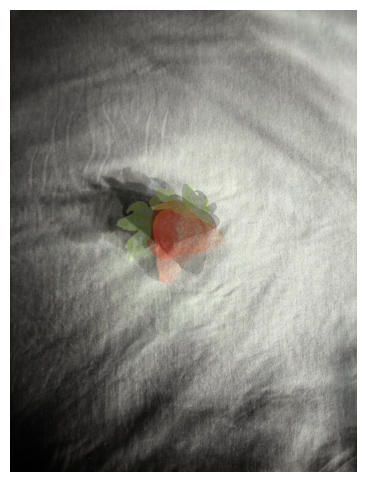

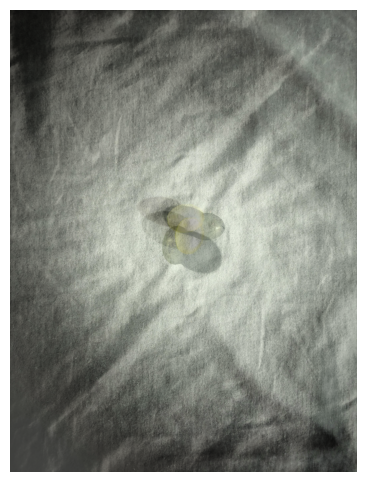

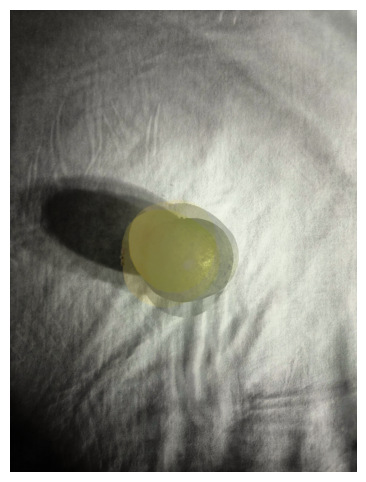

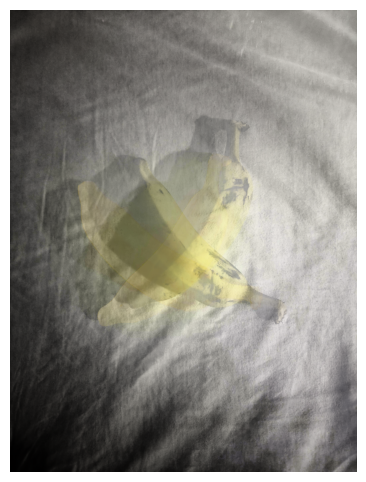

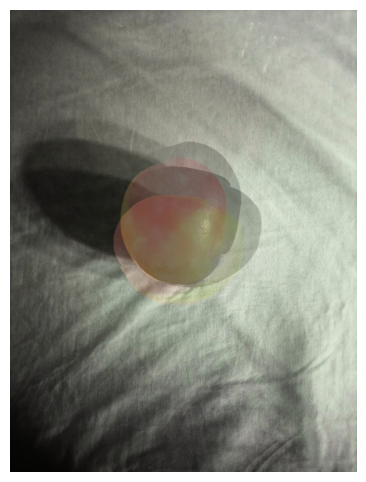

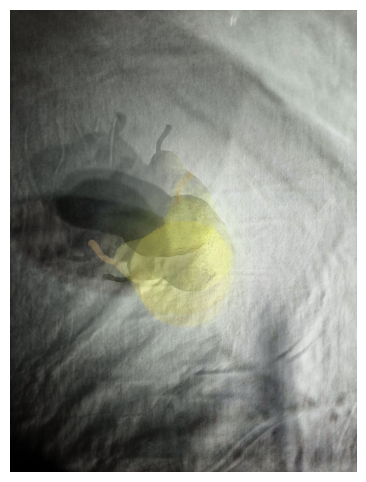

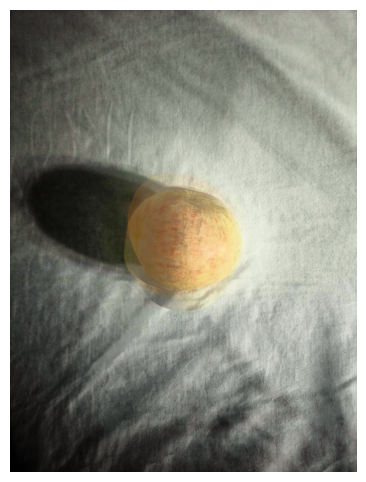

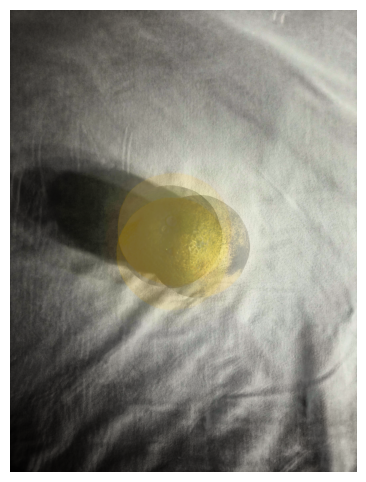

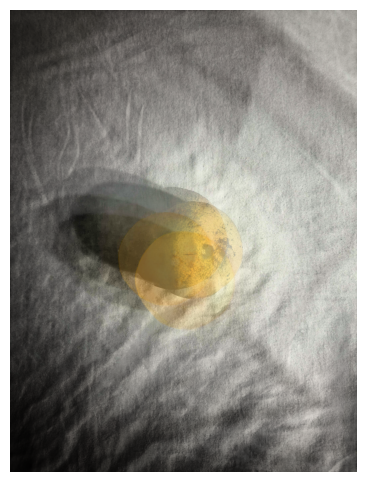

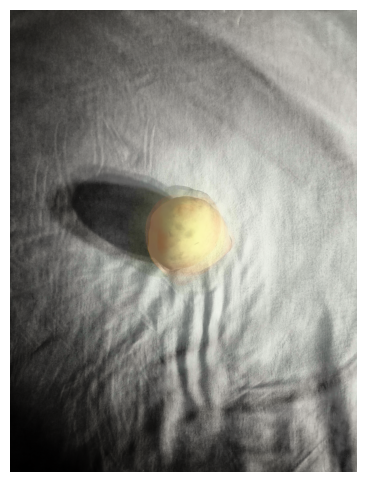

In [23]:
import matplotlib.pyplot as plt
from PIL import Image

for class_id, proto in results_proto.items():
    pil_img = Image.fromarray(proto)
    plt.figure(figsize=(8,6))
    plt.imshow(pil_img)
    plt.axis('off')
    plt.show()

### Show Mean Histogram Results

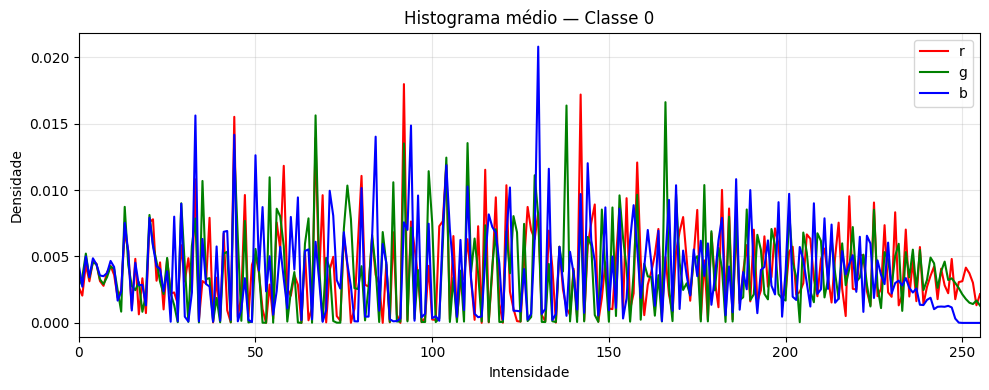

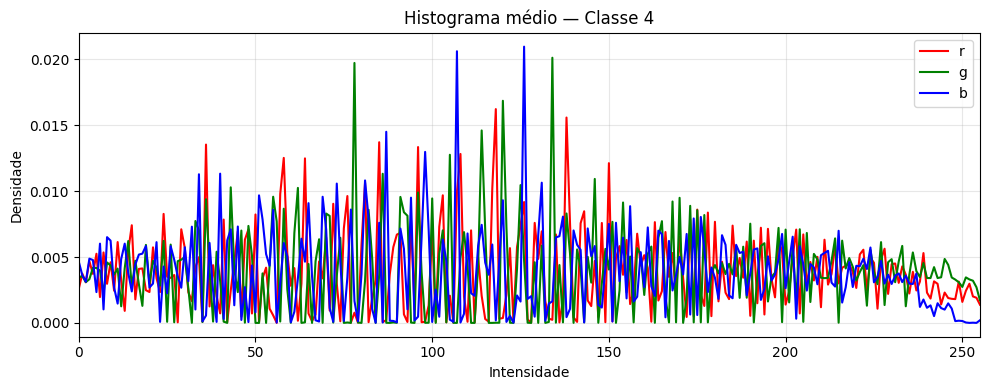

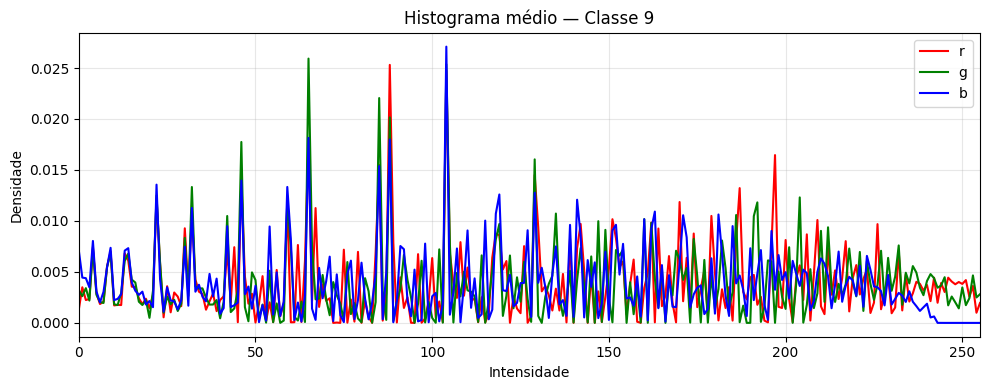

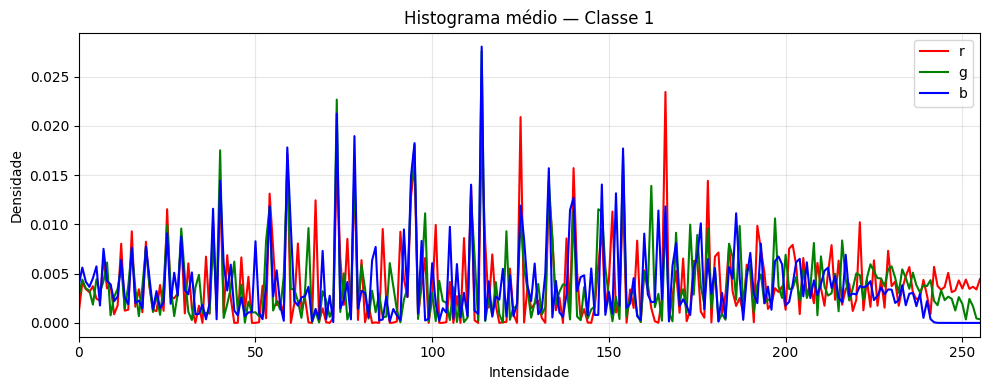

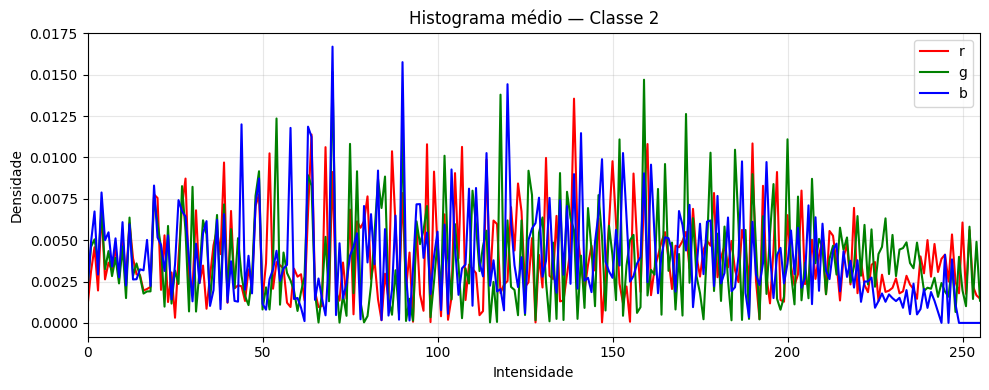

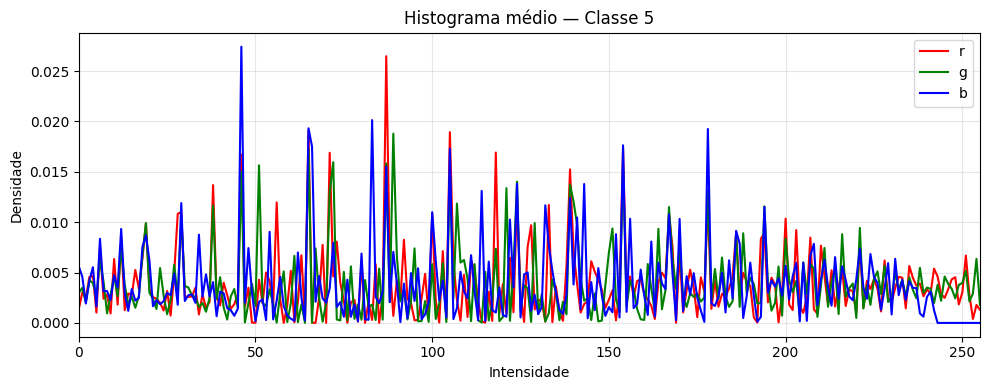

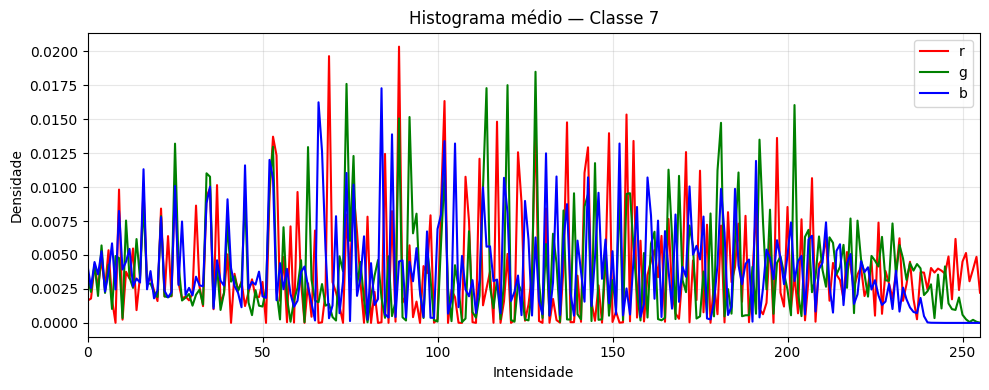

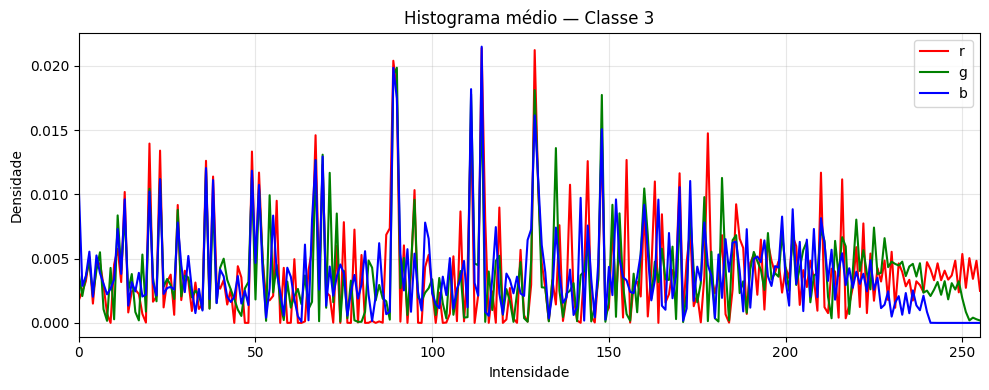

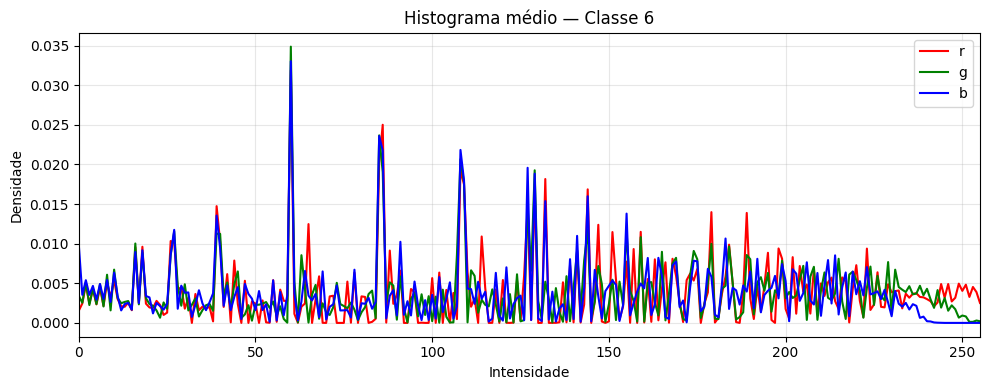

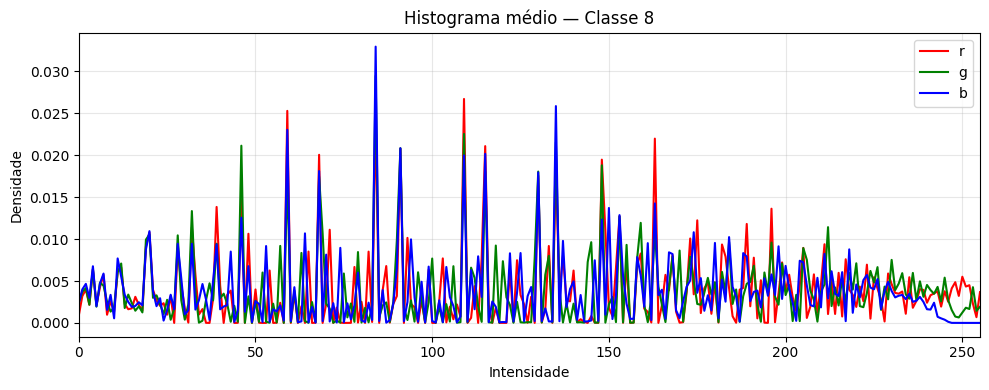

In [24]:
import matplotlib.pyplot as plt

colors_channel = ['red', 'green', 'blue']
colors_names = ['r', 'g', 'b']

n_bins = next(iter(results_h_mean.values())).shape[1]
x = np.arange(n_bins)

for class_id, h_mean in results_h_mean.items():
  plt.figure(figsize=(10, 4))
  for c in range(3):
    plt.plot(x, h_mean[c], color=colors_channel[c], label=colors_names[c])
  plt.title(f'Histograma médio — Classe {class_id}')
  plt.xlabel('Intensidade')
  plt.ylabel('Densidade')
  plt.xlim(0, n_bins - 1)
  plt.legend()
  plt.grid(alpha=0.3)
  plt.tight_layout()

### Show Histogram Variance Results

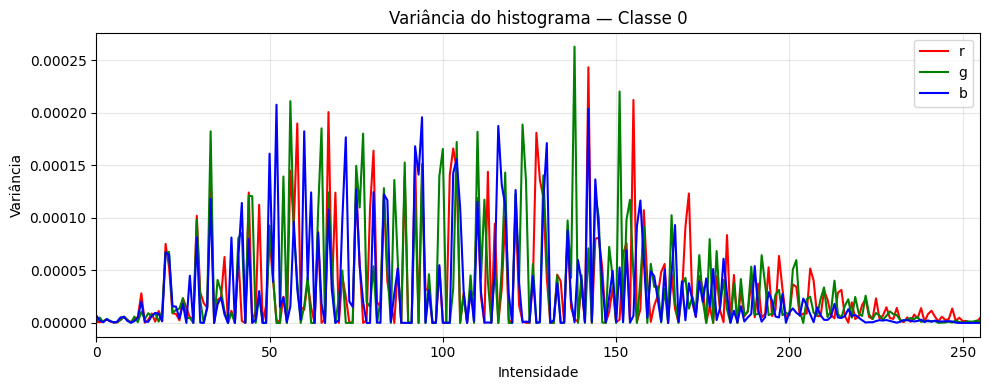

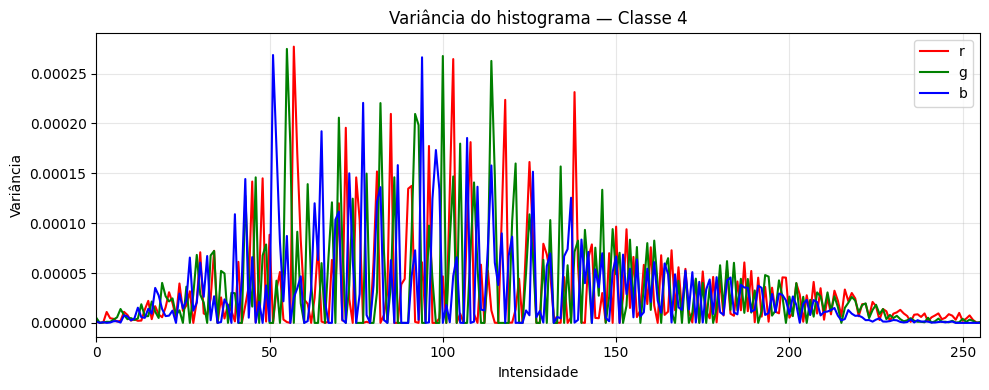

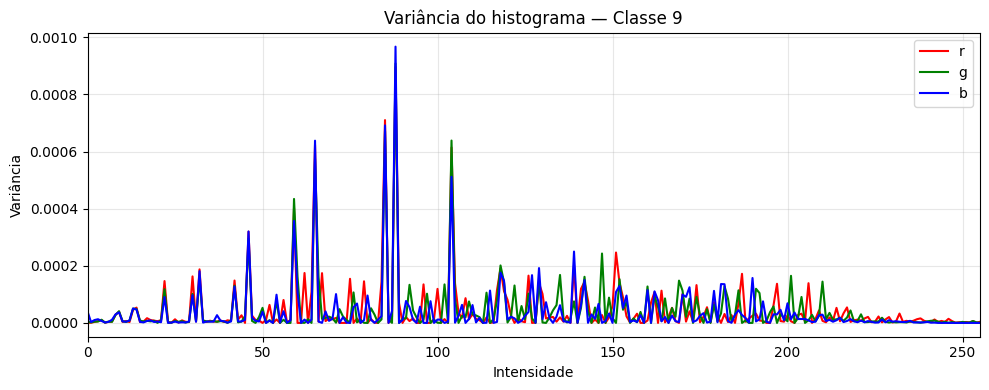

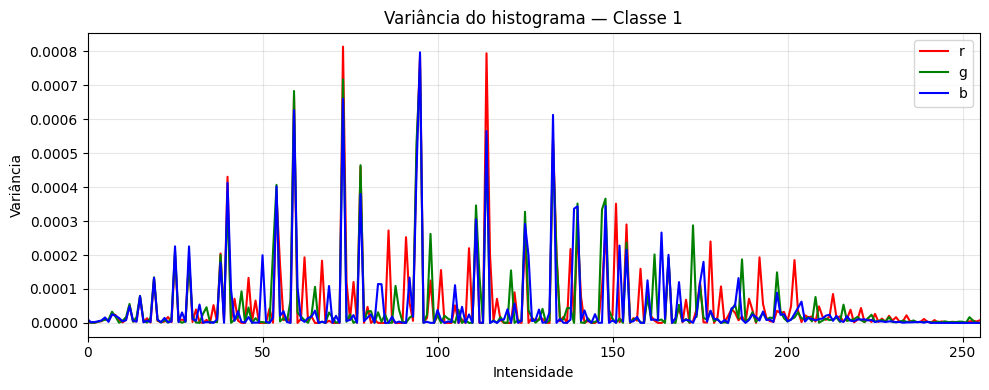

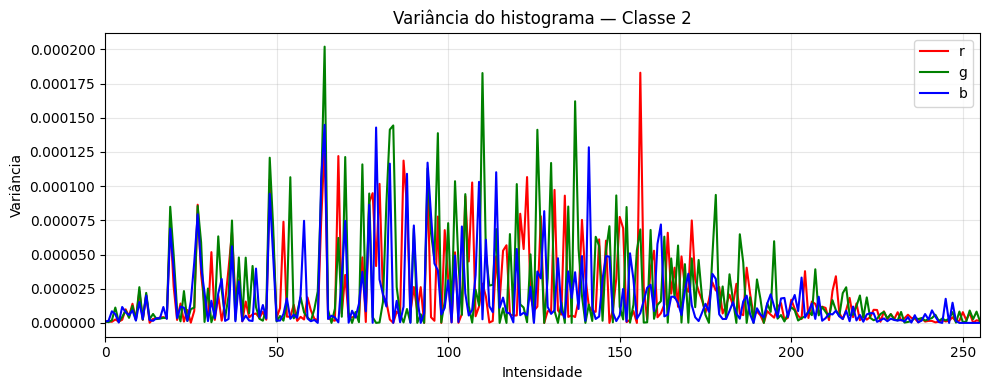

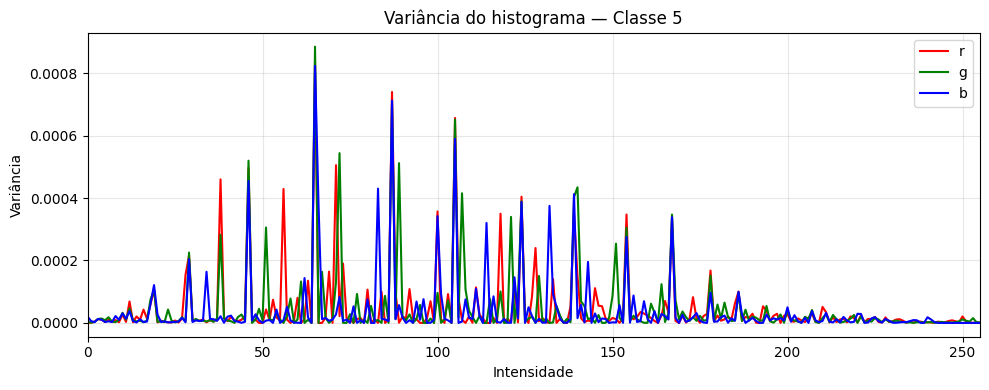

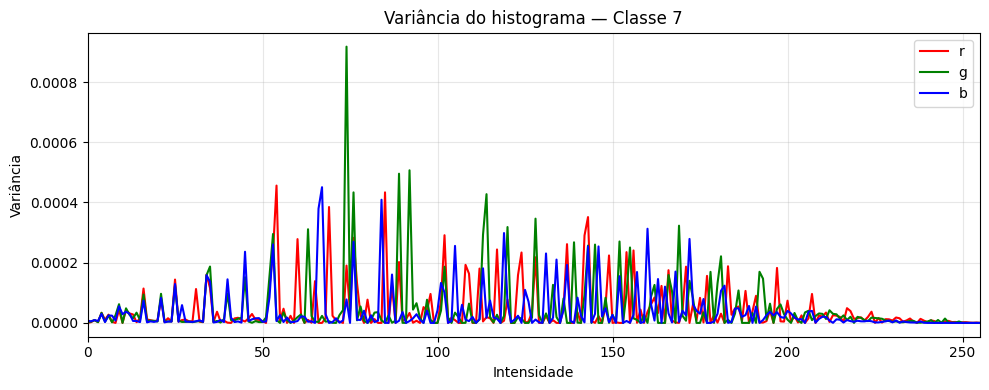

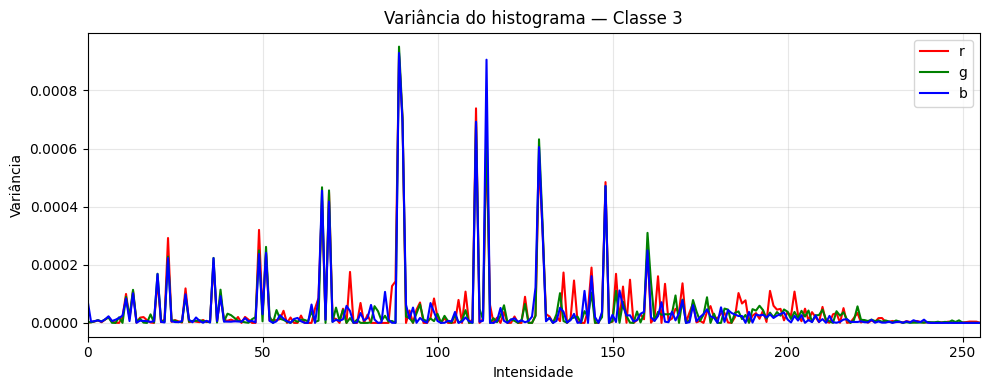

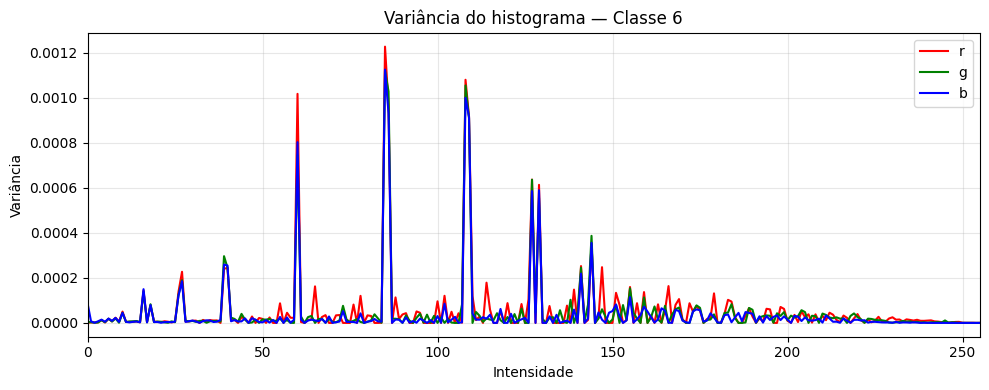

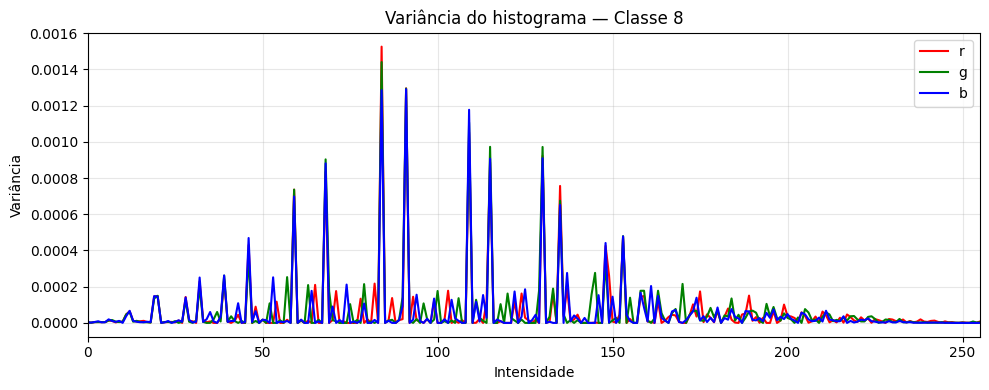

In [26]:
import matplotlib.pyplot as plt

colors_channel = ['red', 'green', 'blue']
colors_names = ['r', 'g', 'b']

n_bins = next(iter(results_h_var.values())).shape[1]
x = np.arange(n_bins)

for class_id, h_var in results_h_var.items():
    plt.figure(figsize=(10, 4))
    for c in range(3):
        plt.plot(x, h_var[c], color=colors_channel[c], label=colors_names[c])

    plt.title(f'Variância do histograma — Classe {class_id}')
    plt.xlabel('Intensidade')
    plt.ylabel('Variância')
    plt.xlim(0, n_bins - 1)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

## 5- Object Segmentation

## 6- Classification